# SC03 Step 4 - Fair Baseline Comparison
This notebook executes a fair benchmark comparison for **SC03: Student Performance and Academic Intervention System**.
The baseline always predicts the most common training label (low); the ANN predictions are the saved Step 3 outputs. Both are compared on exactly the same validation and test rows.
This is **not** a student ranking or disciplinary tool.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'src' / 'compare_baseline.py').is_file():
    ROOT = ROOT.parent

if not (ROOT / 'src' / 'compare_baseline.py').is_file():
    raise FileNotFoundError('Open project folder and ensure src/compare_baseline.py exists.')

sys.path.insert(0, str(ROOT))
print('Project folder:', ROOT)
print('Step 3 metrics exist:', (ROOT / 'data' / 'reports' / 'step3_ann_metrics.csv').is_file())

Project folder: C:\Users\Abhishek\Deepak Softcomputing
Step 3 metrics exist: True


## Run the Same Reproducible Comparison
The Python file checks that saved ANN predictions match the Step 2 split row-for-row. It stops with an error if files are missing or mismatched.

In [2]:
from src import compare_baseline
metrics, comparison = compare_baseline.main()

SC03 STEP 4 - FAIR BASELINE COMPARISON
Training rows: 8400; class counts: {'low': 3737, 'high': 2468, 'medium': 2195}
Majority baseline always predicts: 'low'



Both methods use exactly the same validation/test rows.
     split            method  rows  accuracy  precision  recall  f1_score
validation Majority baseline  1800    0.4450     0.1483  0.3333    0.2053
validation        Step 3 ANN  1800    0.8378     0.8241  0.8206    0.8223
      test Majority baseline  1800    0.4450     0.1483  0.3333    0.2053
      test        Step 3 ANN  1800    0.8383     0.8238  0.8218    0.8227

ANN minus baseline (positive means ANN is higher):
     split    metric  baseline    ann  ann_minus_baseline
validation  accuracy    0.4450 0.8378              0.3928
validation precision    0.1483 0.8241              0.6758
validation    recall    0.3333 0.8206              0.4873
validation  f1_score    0.2053 0.8223              0.6170
      test  accuracy    0.4450 0.8383              0.3933
      test precision    0.1483 0.8238              0.6755
      test    recall    0.3333 0.8218              0.4885
      test  f1_score    0.2053 0.8227              0.6174

## Read the Comparison
nn_minus_baseline is a score difference, not a percentage improvement.
A positive number means the ANN scored higher for that metric on the same split.

,split,method,rows,accuracy,precision,recall,f1_score
0,validation,Majority baseline,1800,0.4450,0.1483,0.3333,0.2053
1,validation,Step 3 ANN,1800,0.8378,0.8241,0.8206,0.8223
2,test,Majority baseline,1800,0.4450,0.1483,0.3333,0.2053
3,test,Step 3 ANN,1800,0.8383,0.8238,0.8218,0.8227


,split,metric,baseline,ann,ann_minus_baseline
0,validation,accuracy,0.4450,0.8378,0.3928
1,validation,precision,0.1483,0.8241,0.6758
2,validation,recall,0.3333,0.8206,0.4873
3,validation,f1_score,0.2053,0.8223,0.6170
4,test,accuracy,0.4450,0.8383,0.3933
5,test,precision,0.1483,0.8238,0.6755
6,test,recall,0.3333,0.8218,0.4885
7,test,f1_score,0.2053,0.8227,0.6174


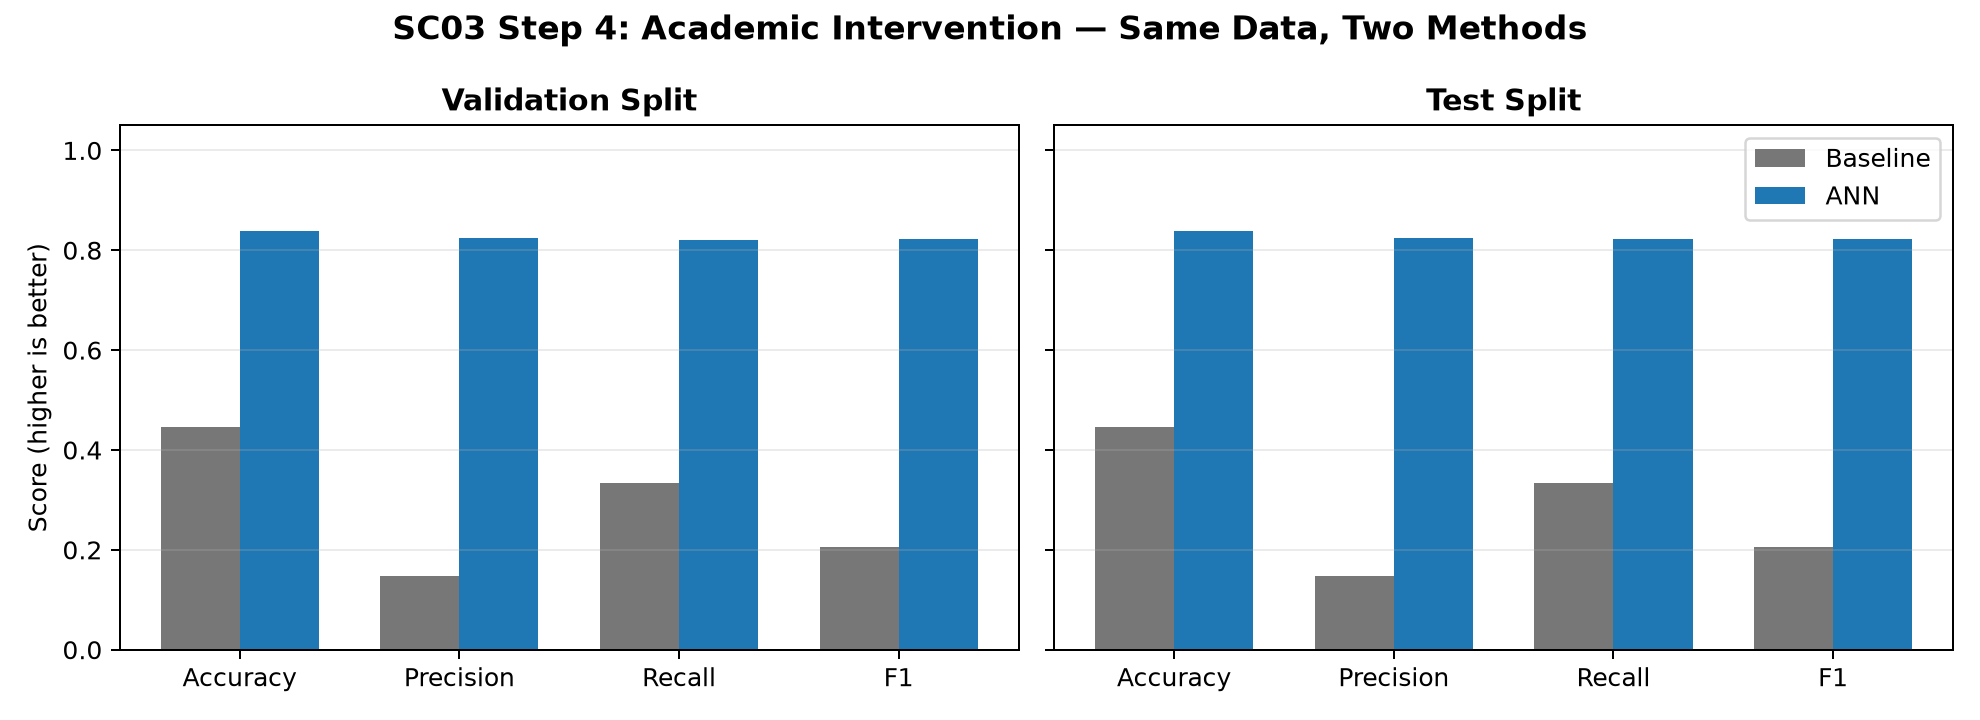

In [3]:
from IPython.display import display, Image
display(metrics)
display(comparison)
display(Image(filename=str(ROOT / 'results' / 'step4_baseline_vs_ann.png')))

## Inspect a Few Paired Predictions
The baseline and ANN columns must refer to the same original row and known label. Do not treat generated testing scenarios as real labelled samples.

In [4]:
import pandas as pd
paired = pd.read_csv(ROOT / 'data' / 'reports' / 'step4_test_paired_predictions.csv')
display(
    paired[['risk_label', 'baseline_prediction', 'ann_prediction']].head(10)
)
print('Test rows compared:', len(paired))

,risk_label,baseline_prediction,ann_prediction
0,medium,low,medium
1,low,low,low
2,low,low,low
3,high,low,high
4,low,low,low
5,high,low,high
6,high,low,high
7,high,low,high
8,medium,low,medium
9,low,low,low


Test rows compared: 1800


## Interpretation and Analysis
The training split contains 8,400 records with distribution:
- low: 3,737 (44.5%)
- high: 2,468 (29.4%)
- medium: 2,195 (26.1%)

Because low is the majority class in training data, the majority baseline predicts low for every single record. Consequently, its accuracy is exactly 44.5% on both validation and test sets, and its recall and precision for medium and high risk students are exactly 0.0. A mentor relying on such a baseline would miss 100% of struggling students who need interventions!

In contrast, the Step 3 ANN learns the complex boundary between learning indicators:
- Validation: Accuracy = 0.8378 (+0.3928 points), Macro F1 = 0.8223 (+0.6170 points).
- Test: Accuracy = 0.8383 (+0.3933 points), Macro F1 = 0.8227 (+0.6174 points).

The neural classifier significantly outperforms the simple heuristic across all metrics, providing actionable decision support.